# **Question 5** 
## Which distribution centers incur the highest logistics costs relative to regional gas prices and can a location for a new facility be derived from this? 

In [4]:
!pip install "trino[sqlalchemy]"

In [1]:
import pandas as pd
from sqlalchemy import create_engine

# Initialize the connection

engine = create_engine("trino://admin@trino:8080/iceberg")

print("Loading tables from datamart...")

# Loading fact and dimension tables
fact_sales = pd.read_sql("SELECT * FROM iceberg.datamart.fact_sales", con=engine)
dim_products = pd.read_sql("SELECT * FROM iceberg.datamart.dim_products", con=engine)
dim_geography = pd.read_sql("SELECT * FROM iceberg.datamart.dim_geography", con=engine)
dim_users = pd.read_sql("SELECT * FROM iceberg.datamart.dim_users", con=engine)
dim_date = pd.read_sql("SELECT * FROM iceberg.datamart.dim_date", con=engine)

print("All tables loaded successfully!")

# Verify row counts
print(f"fact_sales: {len(fact_sales)} rows")
print(f"dim_products: {len(dim_products)} rows")
print(f"dim_geography: {len(dim_geography)} rows")
print(f"dim_users: {len(dim_users)} rows")
print(f"dim_date: {len(dim_date)} rows")


Loading tables from datamart...


All tables loaded successfully!
fact_sales: 181759 rows
dim_products: 29120 rows
dim_geography: 100000 rows
dim_users: 100000 rows
dim_date: 2192 rows


#

### **Create Dashboard Table**

**US Delivery Fleet & Routing Logic:** For short distances (up to 400 miles), we use the Mercedes-Benz Sprinter (avg. 15 MPG); for long distances (over 400 miles), we switch to the Freightliner Cascadia (avg. 7.0 MPG). Because we have no data about the specific routing, we calculate one-way delivery routes using the average geographic coordinates per state in straight-line air miles back to the distribution center using the Haversine formula.

**Used Datamart Tables:**
* `fact_sales`: Contains the core sales transaction data (`order_item_id`, `status`, `created_at`).
* `dim_users` & `dim_geography`: Provide customer location details to map users to their respective US states.
* `dim_products`: Contains product specifications and distribution center locations (`dc_id`, coordinates).
* `dim_date`: Supplies historical macro data for diesel prices (`us_gas_price_diesel_avg`) and time hierarchies.

In [2]:
import numpy as np
import pandas as pd
import os

# Calculate the distance between two points on the Earth in miles using the Haversine formula
def haversine_np(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    return 3956.0 * 2.0 * np.arcsin(np.sqrt(a))

# Filter for US customers (excluding Alaska & Hawaii)
us_users = dim_users[(dim_users['country'] == 'United States') & (~dim_users['state'].isin(['Alaska', 'Hawaii']))]
geo_prep = dim_geography.rename(columns={'state': 'customer_state', 'latitude': 'user_lat', 'longitude': 'user_lon'})

# Combine user info with their geographic data
us_geo = pd.merge(us_users[['user_id']], geo_prep, on='user_id', how='inner')

# Join Fact Table with Customer Geo and Product DC
df = pd.merge(fact_sales, us_geo, on='user_id', how='inner')

# Prepare product data
prod_prep = dim_products[['product_id', 'dc_id', 'dc_city', 'dc_latitude', 'dc_longitude']].rename(
    columns={
        'dc_id': 'distribution_center_id', 
        'dc_latitude': 'dc_lat', 
        'dc_longitude': 'dc_lon'
    }
)

# Join Fact Table with Customer Geo and Product
df = pd.merge(df, prod_prep, on='product_id', how='inner')

# Convert date keys to datetime objects
df['date_key'] = pd.to_datetime(df['date_key'])
dim_date['date_key'] = pd.to_datetime(dim_date['date_key'])

# Join with dim_date
date_columns = ['date_key', 'year', 'quarter', 'month', 'us_gas_price_diesel_avg']
df = pd.merge(df, dim_date[date_columns], on='date_key', how='left')

# format the order date to string (YYYY-MM-DD)
df['order_date'] = pd.to_datetime(df['created_at']).dt.strftime('%Y-%m-%d')


# Include only orders that left the warehouse or completed
# Drop Processing & Cancelled status
df = df[df['status'].isin(['Shipped', 'Complete', 'Returned'])]

# Aggregation per Day & Route
df_logistics = df.groupby(
    ['order_date', 'year', 'quarter', 'month', 'distribution_center_id', 'dc_city', 'customer_state']
).agg(
    total_items    = ('order_item_id', 'count'),
    dc_lat         = ('dc_lat', 'first'),
    dc_lon         = ('dc_lon', 'first'),
    state_lat      = ('user_lat', 'mean'),
    state_lon      = ('user_lon', 'mean'),
    gas_price      = ('us_gas_price_diesel_avg', 'mean') 
).reset_index()

# Calculate Distance & Truck Fuel Costs 
df_logistics['distance_miles'] = haversine_np(
    df_logistics['dc_lon'], df_logistics['dc_lat'],
    df_logistics['state_lon'], df_logistics['state_lat']
).round(2)

# Calculate costs into the column logistics_costs_total
# if distance_miles < 400 = Sprinter(15 MPG), else Cascadia (7 MPG)
df_logistics['assigned_mpg'] = np.where(df_logistics['distance_miles'] < 400, 15.0, 7.0)

df_logistics['logistics_costs_total'] = (
    (df_logistics['distance_miles'] / df_logistics['assigned_mpg']) * df_logistics['gas_price']
).round(2)


df_logistics['order_date'] = pd.to_datetime(df_logistics['order_date'])
df_logistics['dc_city'] = df_logistics['dc_city'].astype('category')
df_logistics['customer_state'] = df_logistics['customer_state'].astype('category')

# Keep in memory for the dashboard select box
dist_centers_dashboard = dim_products[['dc_id', 'dc_city', 'dc_latitude', 'dc_longitude']].drop_duplicates().rename(
    columns={'dc_id': 'id', 'dc_city': 'city', 'dc_latitude': 'latitude', 'dc_longitude': 'longitude'}
)
dist_centers_dashboard['state'] = "USA"

print("Done!")

Done!


In [5]:
df_logistics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23856 entries, 0 to 23855
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   order_date              23856 non-null  datetime64[ns]
 1   year                    23856 non-null  int64         
 2   quarter                 23856 non-null  int64         
 3   month                   23856 non-null  int64         
 4   distribution_center_id  23856 non-null  int64         
 5   dc_city                 23856 non-null  category      
 6   customer_state          23856 non-null  category      
 7   total_items             23856 non-null  int64         
 8   dc_lat                  23856 non-null  float64       
 9   dc_lon                  23856 non-null  float64       
 10  state_lat               23856 non-null  float64       
 11  state_lon               23856 non-null  float64       
 12  gas_price               23856 non-null  float6

In [6]:
df_logistics.head()

,order_date,year,quarter,month,distribution_center_id,dc_city,customer_state,total_items,dc_lat,dc_lon,state_lat,state_lon,gas_price,distance_miles,assigned_mpg,logistics_costs_total
0,2019-01-13,2019,1,1,6,New York,Illinois,1,40.6340,-73.7834,42.231414,-88.327445,3.07,759.96,7.0,333.30
1,2019-01-14,2019,1,1,9,Charleston,Illinois,1,32.7833,-79.9333,42.231414,-88.327445,3.07,797.16,7.0,349.61
2,2019-01-16,2019,1,1,3,Houston,Illinois,1,29.7604,-95.3698,42.231414,-88.327445,3.07,945.80,7.0,414.80
3,2019-01-17,2019,1,1,2,Chicago,California,1,41.8369,-87.6847,32.904701,-116.892628,3.07,1707.00,7.0,748.64
4,2019-01-18,2019,1,1,1,Memphis,California,1,35.1174,-89.9711,32.904701,-116.892628,3.07,1543.67,7.0,677.01


In [ ]:
# Save data as parquet
df_logistics.to_parquet('dashboard_logistics.parquet', index=False)
dist_centers_dashboard.to_parquet('dashboard_distribution_centers.parquet', index=False)

#

##  **Which distribution centers incur the highest logistics costs relative to regional gas prices?**

In [4]:
import plotly.express as px

# Aggregate total logistics costs per distribution center city
df_costs_per_dc = (
    df_logistics.groupby('dc_city', observed=False)['logistics_costs_total']
    .sum()
    .reset_index()
    .sort_values(by='logistics_costs_total', ascending=True) 
)

# horizontal bar chart
fig = px.bar(
    df_costs_per_dc,
    x='logistics_costs_total',
    y='dc_city',
    orientation='h',  
    title='<b>Total Logistics Costs by Distribution Center</b>',
    labels={
        'logistics_costs_total': 'Total Logistics Costs (USD)',
       
    },
   
    color_discrete_sequence=['#1f77b4']
)

# format hover text
fig.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=None,
    yaxis_title=None,
    coloraxis_showscale=False,       
    height=500
)


fig.update_traces(
    hovertemplate="<b>%{y}</b><br>Total Costs: %{x:$,.2f}<extra></extra>"
)


fig.show()

In [13]:
import plotly.express as px

# Aggregate total logistics costs per distribution center city & year
df_costs_stacked = (
    df_logistics.groupby(['dc_city', 'year'], observed=False)['logistics_costs_total']
    .sum()
    .reset_index()
)

# Convert year to string
df_costs_stacked['year'] = df_costs_stacked['year'].astype(str)

# Calculate total
dc_order = (
    df_logistics.groupby('dc_city', observed=False)['logistics_costs_total']
    .sum()
    .sort_values(ascending=False) 
    .index.tolist()
)


my_blues_scale = px.colors.sample_colorscale("Blues", [i/5 for i in range(6)])

# horizontal bar chart
fig = px.bar(
    df_costs_stacked,
    x='logistics_costs_total',
    y='dc_city',
    orientation='h',
    color='year',  # Each year gets its own color
    title='<b>Total Logistics Costs by Distribution Center and Year</b>',
    labels={
        'logistics_costs_total': 'Total Logistics Costs (USD)',
        'dc_city': 'Distribution Center (City)',
        'year': 'Calendar Year'
    },
    category_orders={'dc_city': dc_order}, 
  
    color_discrete_sequence=my_blues_scale 
)


fig.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=None,
    yaxis_title=None,
    height=550,
    legend_title_text='Year',
    barmode='stack' 
)


fig.update_traces(
    hovertemplate="<b>Center: %{y}</b><br>Yearly Share: %{x:$,.2f}<extra></extra>"
)
fig.update_traces(marker_line_width=0)

fig.show()

In [14]:
import plotly.express as px

# Aggregate total items shipped per distribution center city & year
df_items_stacked = (
    df_logistics.groupby(['dc_city', 'year'], observed=False)['total_items']
    .sum()
    .reset_index()
)

# Convert year to string
df_items_stacked['year'] = df_items_stacked['year'].astype(str)

# Calculate total items
dc_order_items = (
    df_logistics.groupby('dc_city', observed=False)['total_items']
    .sum()
    .sort_values(ascending=False) # Highest item volume at the top
    .index.tolist()
)

# Green colorscale
my_greens_scale = px.colors.sample_colorscale("Greens", [i/5 for i in range(6)])

# Stacked horizontal bar
fig = px.bar(
    df_items_stacked,
    x='total_items',
    y='dc_city',
    orientation='h',
    color='year',  
    title='<b>Total Shipped Items by Distribution Center and Year</b>',
    labels={
        'total_items': 'Total Shipped Items (pcs.)',
        'dc_city': 'Distribution Center (City)',
        'year': 'Calendar Year'
    },
    category_orders={'dc_city': dc_order_items}, 
    color_discrete_sequence=my_greens_scale 
)


fig.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=None,
    yaxis_title=None,
    height=550,
    legend_title_text='Year',
    barmode='stack'
)


fig.update_traces(
    hovertemplate="<b>Center: %{y}</b><br>Yearly Volume: %{x:,.0f} pcs.<extra></extra>"
)
fig.update_traces(marker_line_width=0)

fig.show()

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import os
import plotly.io as pio

# Erzwingt den Headless-Modus für den Browser auf dem Server
os.environ["KALEIDO_FLAGS"] = "--headless --no-sandbox --disable-gpu --disable-dev-shm-usage"

# Manchmal hilft es auch, den Export-Modus explizit auf Kaleido zu setzen
pio.renderers.default = "notebook"


df_total = df_logistics.groupby('dc_city', observed=False).agg(
    total_costs=('logistics_costs_total', 'sum'),
    total_items=('total_items', 'sum')
).reset_index()

df_total = df_total.sort_values(by='total_costs', ascending=True)

# Subplots
fig = make_subplots(
    rows=1, cols=2, 
    subplot_titles=('<b>Total Shipped Items (Volume)</b>', '<b>Total Logistics Costs (USD)</b>'),
    shared_yaxes=True  
)

# Left: Volume
fig.add_trace(
    go.Bar(
        x=df_total['total_items'],
        y=df_total['dc_city'],
        orientation='h',
        name='Items (pcs.)',
        marker_color='#2ca02c', 
    ),
    row=1, col=1
)

# Right: Costs
fig.add_trace(
    go.Bar(
        x=df_total['total_costs'],
        y=df_total['dc_city'],
        orientation='h',
        name='Costs ($)',
        marker_color='#1f77b4', 
    ),
    row=1, col=2
)


fig.update_layout(
    title='<b>Logistics Efficiency: Volume vs. Cost Comparison</b>',
    template='plotly_white',
    height=500,
    showlegend=False
)


fig.update_xaxes(tickformat=",.0f", title_text="", row=1, col=1)
fig.update_xaxes(tickformat="$,.2f", title_text="", row=1, col=2)


fig.show()

#### Data shows that Los Angeles incurs the highest overall logistics costs in the US network, despite only ranking 5th in total shipped items.

#

## **Can a location for a new facility be derived from this?**

#### We build a dashboard with Streamlit and Folium to show an interactive map of the USA.

#### Run streamlit run app.py in your terminal to launch the interactive map locally.

```python
import streamlit as st
import pandas as pd
import folium
from streamlit_folium import st_folium


st.set_page_config(
    page_title="Logistics Dashboard",
    page_icon="🚚",
    layout="wide"
)

st.title("🚚 Logistics & Route Analysis")
st.markdown(
    "Analyze transport routes, cargo volumes, and simulated truck fuel costs across multiple distribution centers.")


# Data Load with caching for better performance
@st.cache_data
def load_data():
    # Loads the optimized parquet files from your directory
    df_log = pd.read_parquet('Datamart_Tables/Parquet/dashboard_logistics.parquet')
    df_dc = pd.read_parquet('Datamart_Tables/Parquet/dashboard_distribution_centers.parquet')
    df_log['order_date'] = pd.to_datetime(df_log['order_date'])
    return df_log, df_dc


try:
    df_logistics, dist_centers = load_data()
except FileNotFoundError:
    st.error("❌ The Parquet files were not found. Please verify the path 'Datamart_Tables/Parquet/'.")
    st.stop()


st.sidebar.header("Options")
show_routes = st.sidebar.checkbox("Show Route Connections", value=False)

# Calendar Year (Multiselect)
available_years = sorted(df_logistics['year'].unique())
selected_years = st.sidebar.multiselect(
    "Select Calendar Years:",
    options=available_years,
    default=[available_years[-1]]  # Pre-selects the latest year by default
)

# Distribution Center (Multiselect)
dc_options = sorted(dist_centers['city'].unique())
selected_dc_cities = st.sidebar.multiselect(
    "Select Distribution Centers:",
    options=dc_options,
    default=dc_options  # All DCs are pre-selected by default
)

# Guard Rails: Check if selections are empty
if not selected_years:
    st.warning("⚠️ Please select a Year.")
    st.stop()

if not selected_dc_cities:
    st.warning("⚠️ Please select a Distribution Center.")
    st.stop()

# Restrict data based on selected YEARS and selected DCs
filtered_dcs = dist_centers[dist_centers['city'].isin(selected_dc_cities)]
df_filtered = df_logistics[
    (df_logistics['year'].isin(selected_years)) &
    (df_logistics['dc_city'].isin(selected_dc_cities))
]


# subheader for multiple years
years_display = ", ".join(map(str, sorted(selected_years)))
st.subheader(f"Selected Years: {years_display}")

# KPI cards
total_items_shipped = df_filtered['total_items'].sum()
total_costs = df_filtered['logistics_costs_total'].sum()
avg_distance = df_filtered['distance_miles'].mean()

col1, col2, col3 = st.columns(3)
with col1:
    st.metric(label="Total Items Shipped", value=f"{int(total_items_shipped):,} pcs.")
with col2:
    st.metric(label="Simulated Truck Fuel Costs", value=f"$ {total_costs:,.2f}")
with col3:
    st.metric(label="Ø Transport Distance",
              value=f"{avg_distance:,.1f} miles" if not pd.isna(avg_distance) else "0 miles")

st.markdown("---")

# Folium map


if not df_filtered.empty:
    # Dynamic map center
    if len(selected_dc_cities) == 1:
        dc_coords = filtered_dcs.iloc[0]
        map_center = [dc_coords['latitude'], dc_coords['longitude']]
        zoom_start = 5
    else:
        map_center = [39.5, -98.35]  # US Geographical center
        zoom_start = 4

    m = folium.Map(location=map_center, zoom_start=zoom_start, tiles="cartodbpositron")

    # Unique color palette for lines from different DCs
    colors = ['#1a6faf', '#e31a1c', '#33a02c', '#ff7f00', '#6a3d9a', '#b15928', '#a6cee3', '#b2df8a', '#fdbf6f',
              '#cab2d6']

    # Calculate state centroids for destination circle markers
    state_agg = df_filtered.groupby('customer_state').agg(
        state_lat=('state_lat', 'mean'),
        state_lon=('state_lon', 'mean'),
        total_items=('total_items', 'sum')
    ).reset_index()

    max_orders_state = state_agg['total_items'].max() if not state_agg.empty else 1

    # Draw routes and markers specific to each selected DC
    for idx, (_, dc) in enumerate(filtered_dcs.iterrows()):
        dc_color = colors[idx % len(colors)]

        # Set marker for the distribution center
        folium.Marker(
            location=[dc['latitude'], dc['longitude']],
            popup=folium.Popup(f"<b>CENTER: {dc['city']} ({dc['state']})</b>", max_width=200),
            tooltip=f"DC: {dc['city']}",
            icon=folium.Icon(color='blue', icon='warehouse', prefix='fa')
        ).add_to(m)

        # Filter route data for specific DC
        dc_specific_df = df_filtered[df_filtered['distribution_center_id'] == dc['id']]

        # Aggregate by state for specific DC
        dc_route_agg = dc_specific_df.groupby('customer_state').agg(
            items_route=('total_items', 'sum'),
            costs_route=('logistics_costs_total', 'sum'),
            dest_lat=('state_lat', 'mean'),
            dest_lon=('state_lon', 'mean')
        ).reset_index()

        # Draw connection lines for DC
        for _, route in dc_route_agg.iterrows():
            if route['items_route'] == 0:
                continue

            start_coords = [dc['latitude'], dc['longitude']]
            end_coords = [route['dest_lat'], route['dest_lon']]

            # Dynamic line weight based on item volume
            weight_calc = max(1.0, min(route['items_route'] / 20, 12.0))

            info_text = (
                f"<b>Route:</b> {dc['city']} ➔ {route['customer_state']}<br>"
                f"<b>Volume for Selection:</b> {int(route['items_route'])} pcs.<br>"
                f"<b>Simulated Fuel Costs:</b> $ {route['costs_route']:,.2f}"
            )
            if show_routes:
                folium.PolyLine(
                    locations=[start_coords, end_coords],
                    color=dc_color,
                    weight=weight_calc,
                    opacity=0.4,
                    tooltip=f"{dc['city']} to {route['customer_state']} ({int(route['items_route'])} Items)",
                    popup=folium.Popup(info_text, max_width=300)
                ).add_to(m)


    # Overlay destination centers as green circles
    for _, row in state_agg.iterrows():
        if row['total_items'] == 0:
            continue

        # Radius scales dynamically based on total volume of the destination state
        radius_calc = 5 + (row['total_items'] / max_orders_state) * 15

        folium.CircleMarker(
            location=[row['state_lat'], row['state_lon']],
            radius=radius_calc,
            color='#2ca02c',
            fill=True,
            fill_color='#2ca02c',
            fill_opacity=0.6,
            tooltip=f"Destination State: {row['customer_state']}",
            popup=f"<b>State: {row['customer_state']}</b><br>Total Volume: {int(row['total_items'])} pcs."
        ).add_to(m)

    # Render map
    st_folium(m, use_container_width=True, height=800, returned_objects=[])

else:
    st.info("ℹ️ No data available.")

#### The Dashboard output shows us the following facts:

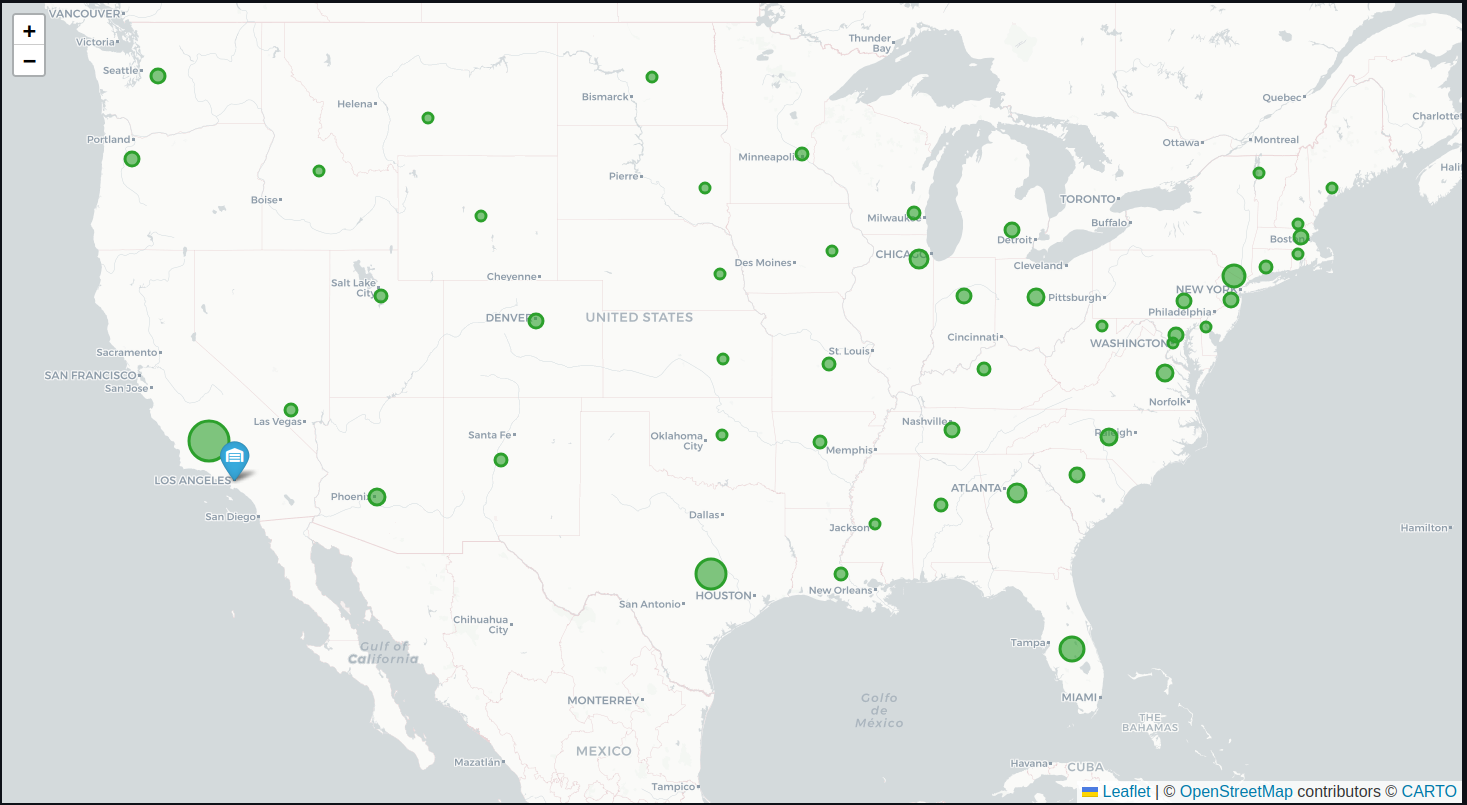

In [9]:
from IPython.display import Image, display

display(Image(filename='dc_la.png', width=800))

##### The map highlights the Los Angeles distribution center (blue marker) and its delivery destinations per state (green bubbles).
##### The bubble locations represent the average geographic centroids of all customer destinations calculated via the Haversine formula, while the bubble size reflects the dynamic order volume per state.
##### Notably, the LA hub fulfills a vast amount of orders not only locally in California but also far across the country near Houston and the East Coast.
##### This operational overlap exposes severe cross-country inefficiencies.

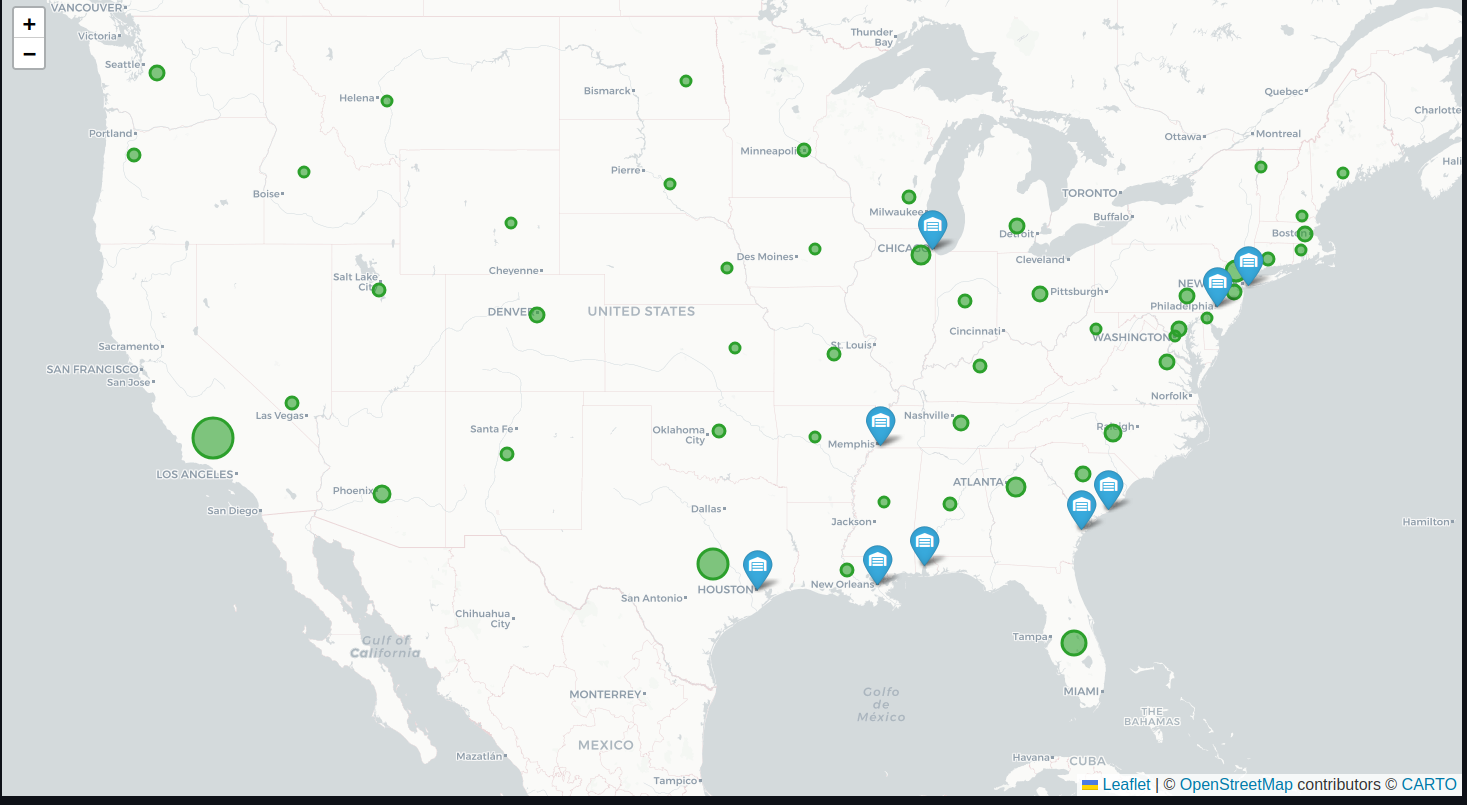

In [10]:
from IPython.display import Image, display

display(Image(filename='dc_without_la.png', width=800))

##### For comparison, this map displays all active distribution centers in the network, excluding Los Angeles.
##### It uncovers a major structural issue: the network frequently bypasses closer local facilities, shipping the majority of East and West Coast articles all the way to California.
##### This cross-routing further confirms a highly inefficient allocation of delivery zones.

#

## **Conclusion: Network Inefficiency & New Facility Derivation**

---

### 1. Highest Logistics Costs (Los Angeles)
The data identifies the **Los Angeles distribution center (DC) as the primary cost driver** across the entire US network. Since this simulation utilizes a uniform, average US diesel price (`us_gas_price_diesel_avg`), the cost metric effectively isolates the driven miles and vehicle selection as the primary factors. 

A massive discrepancy between volume and costs is revealed: **Although LA ranks only 5th in total volume (Shipped Items), it incurs the highest overall logistics costs in the network.**

### 2. Root Cause: Cross-Routing
The Folium maps clearly visualize the underlying cause of this financial inefficiency: a severe **cross-routing problem**. 
* The Los Angeles DC heavily services regions on the East Coast and in Texas (long-haul routes $\ge 400$ miles using the fuel-intensive *Freightliner Cascadia*). 
* At the same time, delivery zones overlap significantly, as items from eastern DCs are shipped across the country to California instead of fulfilling local demand nearby.

### 3. Strategic Derivation for a New Facility (Salt Lake City)
Based on this spatial pattern, the placement of a new logistics hub in **Salt Lake City (Utah)** can be strategically derived. Geographically and logistically, Salt Lake City is widely recognized as the *"Crossroads of the West"*. 

Establishing a facility there offers three strategic advantages:

* **Relieving the LA Hub:** It intercepts eastbound long-haul shipments. This allows the Los Angeles DC to focus on regional distribution (short-haul routes $< 400$ miles using the highly efficient *MB Sprinter*).
* **Reduce Cross-Routing:** It acts as a logistics buffer and consolidation point for East-to-West and West-to-East cross routing and reducing the average transport distance across the entire network.
* **Infrastructure Advantage:** Salt Lake City provides an excellent transport network through the intersection of major Interstates (I-15 and I-80), a large rail grid network (Union Pacific Hub), and a international airport, ensuring optimal coverage for the entire Western United States.

#

## **Project lecture**

##### For presentation we integrate the plotly charts into the Streamlit dashboard

```python
import streamlit as st
import pandas as pd
import folium
from streamlit_folium import st_folium
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


st.set_page_config(
    page_title="Logistics Dashboard",
    page_icon="🚚",
    layout="wide"
)

st.title("🚚 Logistics & Route Analysis")
st.markdown(
    "Analyze transport routes, cargo volumes, and simulated truck fuel costs across multiple distribution centers.")


@st.cache_data
def load_data():
    df_log = pd.read_parquet('Datamart_Tables/Parquet/dashboard_logistics.parquet')
    df_dc = pd.read_parquet('Datamart_Tables/Parquet/dashboard_distribution_centers.parquet')
    df_log['order_date'] = pd.to_datetime(df_log['order_date'])
    return df_log, df_dc


try:
    df_logistics, dist_centers = load_data()
except FileNotFoundError:
    st.error("❌ The Parquet files were not found. Please verify the path 'Datamart_Tables/Parquet/'.")
    st.stop()


st.sidebar.header("Options")
show_routes = st.sidebar.checkbox("Show Route Connections", value=False)

available_years = sorted(df_logistics['year'].unique())
selected_years = st.sidebar.multiselect(
    "Select Calendar Years:",
    options=available_years,
    default=[available_years[-1]]
)

dc_options = sorted(dist_centers['city'].unique())
selected_dc_cities = st.sidebar.multiselect(
    "Select Distribution Centers:",
    options=dc_options,
    default=dc_options
)

if not selected_years:
    st.warning("⚠️ Please select a Year.")
    st.stop()

if not selected_dc_cities:
    st.warning("⚠️ Please select a Distribution Center.")
    st.stop()

filtered_dcs = dist_centers[dist_centers['city'].isin(selected_dc_cities)]
df_filtered = df_logistics[
    (df_logistics['year'].isin(selected_years)) &
    (df_logistics['dc_city'].isin(selected_dc_cities))
]

years_display = ", ".join(map(str, sorted(selected_years)))
st.subheader(f"Selected Years: {years_display}")

total_items_shipped = df_filtered['total_items'].sum()
total_costs = df_filtered['logistics_costs_total'].sum()
avg_distance = df_filtered['distance_miles'].mean()

col1, col2, col3 = st.columns(3)
with col1:
    st.metric(label="Total Items Shipped", value=f"{int(total_items_shipped):,} pcs.")
with col2:
    st.metric(label="Simulated Truck Fuel Costs", value=f"$ {total_costs:,.2f}")
with col3:
    st.metric(label="Ø Transport Distance",
              value=f"{avg_distance:,.1f} miles" if not pd.isna(avg_distance) else "0 miles")

st.markdown("---")

# --- Folium Map ---

if not df_filtered.empty:
    if len(selected_dc_cities) == 1:
        dc_coords = filtered_dcs.iloc[0]
        map_center = [dc_coords['latitude'], dc_coords['longitude']]
        zoom_start = 5
    else:
        map_center = [39.5, -98.35]
        zoom_start = 4

    m = folium.Map(location=map_center, zoom_start=zoom_start, tiles="cartodbpositron")

    colors = ['#1a6faf', '#e31a1c', '#33a02c', '#ff7f00', '#6a3d9a', '#b15928', '#a6cee3', '#b2df8a', '#fdbf6f',
              '#cab2d6']

    state_agg = df_filtered.groupby('customer_state').agg(
        state_lat=('state_lat', 'mean'),
        state_lon=('state_lon', 'mean'),
        total_items=('total_items', 'sum')
    ).reset_index()

    max_orders_state = state_agg['total_items'].max() if not state_agg.empty else 1

    for idx, (_, dc) in enumerate(filtered_dcs.iterrows()):
        dc_color = colors[idx % len(colors)]

        folium.Marker(
            location=[dc['latitude'], dc['longitude']],
            popup=folium.Popup(f"<b>CENTER: {dc['city']} ({dc['state']})</b>", max_width=200),
            tooltip=f"DC: {dc['city']}",
            icon=folium.Icon(color='blue', icon='warehouse', prefix='fa')
        ).add_to(m)

        dc_specific_df = df_filtered[df_filtered['distribution_center_id'] == dc['id']]

        dc_route_agg = dc_specific_df.groupby('customer_state').agg(
            items_route=('total_items', 'sum'),
            costs_route=('logistics_costs_total', 'sum'),
            dest_lat=('state_lat', 'mean'),
            dest_lon=('state_lon', 'mean')
        ).reset_index()

        for _, route in dc_route_agg.iterrows():
            if route['items_route'] == 0:
                continue

            start_coords = [dc['latitude'], dc['longitude']]
            end_coords = [route['dest_lat'], route['dest_lon']]
            weight_calc = max(1.0, min(route['items_route'] / 20, 12.0))

            info_text = (
                f"<b>Route:</b> {dc['city']} ➔ {route['customer_state']}<br>"
                f"<b>Volume for Selection:</b> {int(route['items_route'])} pcs.<br>"
                f"<b>Simulated Fuel Costs:</b> $ {route['costs_route']:,.2f}"
            )
            if show_routes:
                folium.PolyLine(
                    locations=[start_coords, end_coords],
                    color=dc_color,
                    weight=weight_calc,
                    opacity=0.4,
                    tooltip=f"{dc['city']} to {route['customer_state']} ({int(route['items_route'])} Items)",
                    popup=folium.Popup(info_text, max_width=300)
                ).add_to(m)

    for _, row in state_agg.iterrows():
        if row['total_items'] == 0:
            continue

        radius_calc = 5 + (row['total_items'] / max_orders_state) * 15

        folium.CircleMarker(
            location=[row['state_lat'], row['state_lon']],
            radius=radius_calc,
            color='#2ca02c',
            fill=True,
            fill_color='#2ca02c',
            fill_opacity=0.6,
            tooltip=f"Destination State: {row['customer_state']}",
            popup=f"<b>State: {row['customer_state']}</b><br>Total Volume: {int(row['total_items'])} pcs."
        ).add_to(m)

    st_folium(m, use_container_width=True, height=800, returned_objects=[])

else:
    st.info("ℹ️ No data available.")

st.markdown("---")

# Chart 1: Total Logistics Costs by Distribution Center
df_costs_per_dc = (
    df_filtered.groupby('dc_city', observed=False)['logistics_costs_total']
    .sum()
    .reset_index()
    .sort_values(by='logistics_costs_total', ascending=True)
)

fig1 = px.bar(
    df_costs_per_dc,
    x='logistics_costs_total',
    y='dc_city',
    orientation='h',
    title='<b>Total Logistics Costs by Distribution Center</b>',
    labels={'logistics_costs_total': '', 'dc_city': ''},
    color_discrete_sequence=['#1f77b4']
)

fig1.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=dict(tickformat="$,.2f", title_text=''),
    yaxis=dict(title_text=''),
    coloraxis_showscale=False,
    height=500
)

fig1.update_traces(
    hovertemplate="<b>%{y}</b><br>Total Costs: %{x:$,.2f}<extra></extra>"
)

st.plotly_chart(fig1, use_container_width=True)

st.markdown("---")

# Chart 2: Stacked – Total Logistics Costs by DC and Year
df_costs_stacked = (
    df_filtered.groupby(['dc_city', 'year'], observed=False)['logistics_costs_total']
    .sum()
    .reset_index()
)
df_costs_stacked['year'] = df_costs_stacked['year'].astype(str)

dc_order = (
    df_filtered.groupby('dc_city', observed=False)['logistics_costs_total']
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

my_blues_scale = px.colors.sample_colorscale("Blues", [i / 5 for i in range(6)])

fig2 = px.bar(
    df_costs_stacked,
    x='logistics_costs_total',
    y='dc_city',
    orientation='h',
    color='year',
    title='<b>Total Logistics Costs by Distribution Center and Year</b>',
    labels={'logistics_costs_total': '', 'dc_city': '', 'year': 'Calendar Year'},
    category_orders={'dc_city': dc_order},
    color_discrete_sequence=my_blues_scale
)

fig2.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=dict(tickformat="$,.2f", title_text=''),
    yaxis=dict(title_text=''),
    height=550,
    legend_title_text='Year',
    barmode='stack'
)

fig2.update_traces(
    hovertemplate="<b>Center: %{y}</b><br>Yearly Share: %{x:$,.2f}<extra></extra>"
)
fig2.update_traces(marker_line_width=0)

st.plotly_chart(fig2, use_container_width=True)

st.markdown("---")

# Chart 3: Stacked – Total Shipped Items by DC and Year
df_items_stacked = (
    df_filtered.groupby(['dc_city', 'year'], observed=False)['total_items']
    .sum()
    .reset_index()
)
df_items_stacked['year'] = df_items_stacked['year'].astype(str)

dc_order_items = (
    df_filtered.groupby('dc_city', observed=False)['total_items']
    .sum()
    .sort_values(ascending=False)
    .index.tolist()
)

my_greens_scale = px.colors.sample_colorscale("Greens", [i / 5 for i in range(6)])

fig3 = px.bar(
    df_items_stacked,
    x='total_items',
    y='dc_city',
    orientation='h',
    color='year',
    title='<b>Total Shipped Items by Distribution Center and Year</b>',
    labels={'total_items': '', 'dc_city': '', 'year': 'Calendar Year'},
    category_orders={'dc_city': dc_order_items},
    color_discrete_sequence=my_greens_scale
)

fig3.update_layout(
    template='plotly_white',
    title_font_size=20,
    xaxis=dict(tickformat=",.0f", title_text=''),
    yaxis=dict(title_text=''),
    height=550,
    legend_title_text='Year',
    barmode='stack'
)

fig3.update_traces(
    hovertemplate="<b>Center: %{y}</b><br>Yearly Volume: %{x:,.0f} pcs.<extra></extra>"
)
fig3.update_traces(marker_line_width=0)

st.plotly_chart(fig3, use_container_width=True)

st.markdown("---")

# Chart 4: Subplot – Volume vs. Cost Comparison
df_total = df_filtered.groupby('dc_city', observed=False).agg(
    total_costs=('logistics_costs_total', 'sum'),
    total_items=('total_items', 'sum')
).reset_index()

df_total = df_total.sort_values(by='total_costs', ascending=True)

fig4 = make_subplots(
    rows=1, cols=2,
    subplot_titles=('<b>Total Shipped Items (Volume)</b>', '<b>Total Logistics Costs (USD)</b>'),
    shared_yaxes=True
)

fig4.add_trace(
    go.Bar(
        x=df_total['total_items'],
        y=df_total['dc_city'],
        orientation='h',
        name='Items (pcs.)',
        marker_color='#2ca02c',
    ),
    row=1, col=1
)

fig4.add_trace(
    go.Bar(
        x=df_total['total_costs'],
        y=df_total['dc_city'],
        orientation='h',
        name='Costs ($)',
        marker_color='#1f77b4',
    ),
    row=1, col=2
)

fig4.update_layout(
    title='<b>Logistics Efficiency: Volume vs. Cost Comparison</b>',
    template='plotly_white',
    height=500,
    showlegend=False
)

fig4.update_xaxes(tickformat=",.0f", title_text='', row=1, col=1)
fig4.update_xaxes(tickformat="$,.2f", title_text='', row=1, col=2)

st.plotly_chart(fig4, use_container_width=True)
